In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm

from taia1dvfd.analysis import get_model_variable

In [ ]:
OUT = "/home/mnex/Desktop/1DV_FD/experiments/5_Eco3M_lotus/output/"
FILE = OUT + "eco3M_lotus.nc"
NDAYS = 160

In [3]:
def load(name):
    z, t, mean, var = get_model_variable(FILE, name)
    return z, t / 86400.0, mean, var

def daily_mean(t, x, n_days):
    day = np.floor(t).astype(int)
    out = np.full(n_days, np.nan)
    for d in range(n_days):
        sel = (day == d) & np.isfinite(x)
        if sel.any():
            out[d] = x[sel].mean()
    return np.arange(n_days) + 0.5, out

def _hov(ax, t, z, field, label, log=False, cmap="viridis"):
    pos = field[field > 0]
    if log and pos.size:
        norm = LogNorm(vmin=max(pos.min(), pos.max() * 1e-5), vmax=pos.max())
        field = np.where(field > 0, field, np.nan)
    else:
        norm = None
    pc = ax.pcolormesh(t, z, field.T, shading="nearest", norm=norm, cmap=cmap)        
    ax.set_ylabel("Depth (m)")
    plt.colorbar(pc, ax=ax, label=label, pad=0.01)
    return pc

Text(0.5, 1.0, 'Temperature')

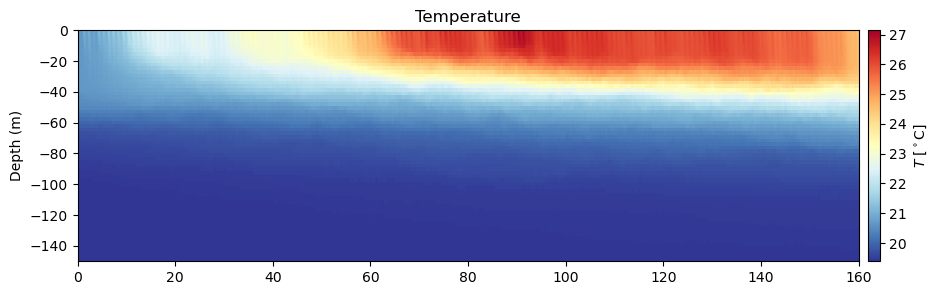

In [4]:
z, t, temp, _ = load("temp")

fig, ax = plt.subplots(1, 1, figsize=(12, 3), sharex=True)
_hov(ax, t, z, temp, r"$T$ [$^\circ$C]", cmap="RdYlBu_r")
ax.set_title("Temperature")

Text(0.5, 0, 'Time (days)')

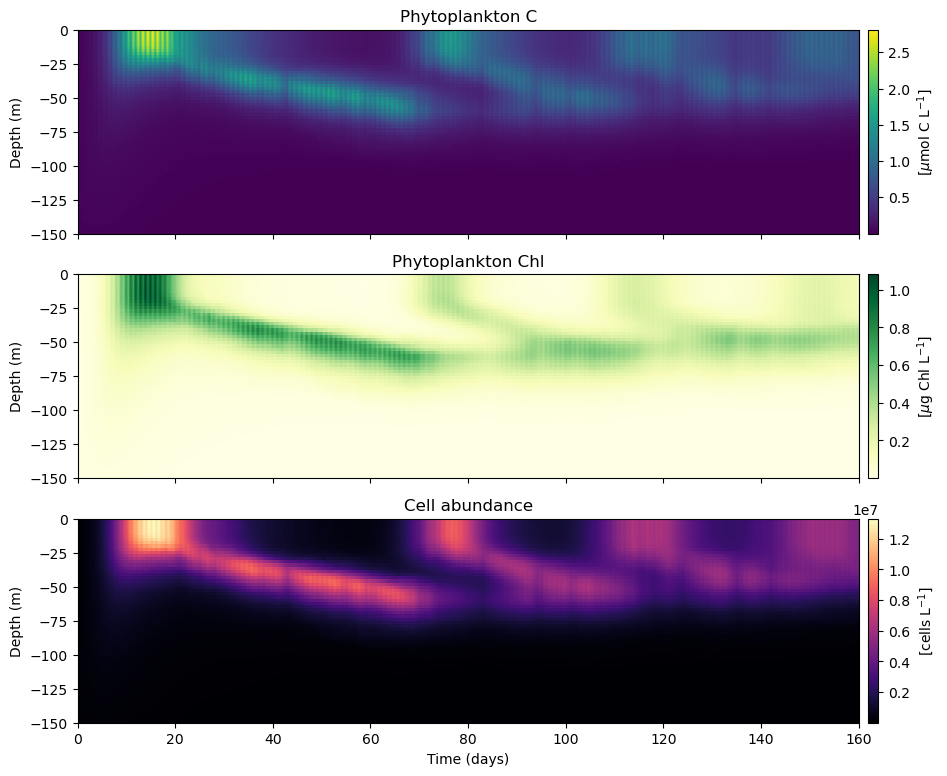

In [5]:
z, t, c, _ = load("bgc_phy_PHY_C")
_, _, chl, _ = load("bgc_phy_PHY_Chl")
_, _, cell, _ = load("bgc_phy_PHY_cell")

fig, axs = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
_hov(axs[0], t, z, c * 1e6, r"[$\mu$mol C L$^{-1}$]")
axs[0].set_title("Phytoplankton C")

_hov(axs[1], t, z, chl * 1e6, r"[$\mu$g Chl L$^{-1}$]", cmap="YlGn")
axs[1].set_title("Phytoplankton Chl")

_hov(axs[2], t, z, cell, r"[cells L$^{-1}$]", cmap="magma")
axs[2].set_title("Cell abundance")
axs[2].set_xlabel("Time (days)")

# Phytoplankton Chlorophyll

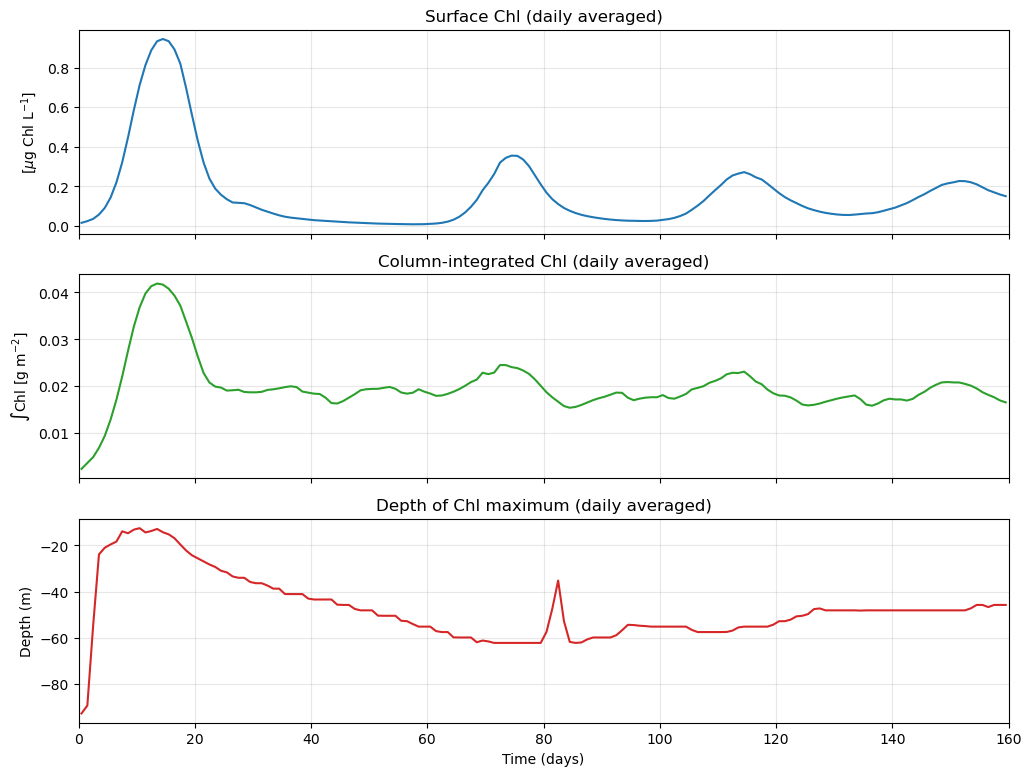

In [9]:
z, t, chl, _ = load("bgc_phy_PHY_Chl")
td, chl_srf = daily_mean(t, chl[:, 0], NDAYS)

fig, ax = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
ax[0].plot(td, chl_srf*1e6, color = 'C0')
ax[0].set_title("Surface Chl (daily averaged)")
ax[0].set_ylabel(r"[$\mu$g Chl L$^{-1}$]")
ax[0].grid(alpha = 0.3)
ax[0].set_xlim(0, NDAYS)

dz = abs(z[1] - z[0])
int_chl = chl.sum(axis=1) * dz * 1e3    # g Chl m-2
td, int_chl = daily_mean(t, int_chl, NDAYS)

ax[1].set_title("Column-integrated Chl (daily averaged)")
ax[1].plot(td, int_chl, color="C2")
ax[1].set_ylabel(r"$\int$Chl [g m$^{-2}$]")
ax[1].grid(alpha=0.3)

# Depth of the chlorophyll maximum
z_dcm = z[np.argmax(chl, axis=1)]
td, z_dcm = daily_mean(t, z_dcm, NDAYS)

ax[2].set_title("Depth of Chl maximum (daily averaged)")
ax[2].plot(td, z_dcm, color = 'C3')
ax[2].set_ylabel("Depth (m)")
ax[2].set_xlabel("Time (days)")
ax[2].grid(alpha=0.3)